# Cafe Sales Data Analysis

## 1. Project Overview

This project analyzes a cafe sales dataset containing 10,000 transactions.

The dataset contains information about products, quantities, prices, transaction values, payment methods, locations, and transaction dates.

### Objectives

* Clean and prepare the raw sales data.
* Handle missing and invalid values.
* Validate numerical relationships within the dataset.
* Analyze product and revenue performance.
* Identify monthly and weekly sales patterns.
* Analyze payment methods and locations.
* Create visualizations to communicate key findings.
* Prepare the cleaned data for SQL/MySQL analysis.

### Tools and Technologies

* Python
* Pandas
* NumPy
* Matplotlib
* MySQL / SQL
* Kaggle
* GitHub


## 2. Import Libraries and Load Dataset

In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/input/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training/dirty_cafe_sales.csv"
)

df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


## 3. Initial Data Inspection

In [229]:
df.shape

(10000, 8)

In [230]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [231]:
df.describe(include="all")

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [232]:
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

## 4.Data cleaning

In [233]:
# Replace invalid values with NaN

invalid_values = ["UNKNOWN", "ERROR"]

columns_to_clean = [
    "Item",
    "Payment Method",
    "Location",
    "Transaction Date"
]

for column in columns_to_clean:
    df[column] = df[column].replace(invalid_values, np.nan)

In [234]:
# Convert numerical columns to numeric data types

numeric_columns = [
    "Quantity",
    "Price Per Unit",
    "Total Spent"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [235]:
# Convert Transaction Date to datetime

df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)

## 5. Recover Missing Numerical Values

### 5.1 Recover missing Price Per Unit using Item

In [236]:
# Get the known price for each item

item_price = df.groupby("Item")["Price Per Unit"].first()

item_price

Item
Cake        3.0
Coffee      2.0
Cookie      1.0
Juice       3.0
Salad       5.0
Sandwich    4.0
Smoothie    4.0
Tea         1.5
Name: Price Per Unit, dtype: float64

In [237]:
# Fill missing prices using the item's known price

df["Price Per Unit"] = df["Price Per Unit"].fillna(
    df["Item"].map(item_price)
)

### 5.2 Recover remaining missing Price Per Unit

In [238]:
# Calculate missing prices from Total Spent and Quantity

calculated_price = (
    df["Total Spent"] / df["Quantity"]
)

df["Price Per Unit"] = df["Price Per Unit"].fillna(
    calculated_price
)

### 5.3 Recover missing Quantity

In [239]:
# Calculate missing quantities

calculated_quantity = (
    df["Total Spent"] / df["Price Per Unit"]
)

df["Quantity"] = df["Quantity"].fillna(
    calculated_quantity
)

### 5.4 Recover missing Total Spent

In [240]:
# Calculate missing total spent values

calculated_total = (
    df["Quantity"] * df["Price Per Unit"]
)

df["Total Spent"] = df["Total Spent"].fillna(
    calculated_total
)

## 6. Data Validation

### 6.1 Check missing values

In [241]:
# Check missing values after cleaning

df.isnull().sum()

Transaction ID         0
Item                 969
Quantity              23
Price Per Unit         6
Total Spent           23
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

### 6.2. Validate Total Spent

In [242]:
calculated_total = df["Quantity"] * df["Price Per Unit"]

valid_rows = (
    df["Quantity"].notna() &
    df["Price Per Unit"].notna()
)

total_check = np.isclose(
    df.loc[valid_rows, "Total Spent"],
    calculated_total.loc[valid_rows],
    equal_nan=True
)

pd.Series(total_check).value_counts()

True    9974
Name: count, dtype: int64

In [243]:
# Show rows where Total Spent does not match Quantity * Price Per Unit

mismatch = pd.Series(False, index=df.index)

mismatch.loc[valid_rows] = ~total_check

df.loc[
    mismatch,
    [
        "Transaction ID",
        "Item",
        "Quantity",
        "Price Per Unit",
        "Total Spent"
    ]
]

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent


### 6.3 Check Duplicate Transactions

In [244]:
# Check for duplicate transactions

df["Transaction ID"].duplicated().sum()

np.int64(0)

## 7. Exploratory Data Analysis
This section analyzes sales performance across products, time periods, payment methods, locations, and transaction values.

### 7.1 Overall Business Summary

In [245]:
# Calculate overall business metrics

total_revenue = df["Total Spent"].sum()
average_transaction = df["Total Spent"].mean()
average_quantity = df["Quantity"].mean()
average_price = df["Price Per Unit"].mean()

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Average Transaction Value: {average_transaction:.2f}")
print(f"Average Quantity per Transaction: {average_quantity:.2f}")
print(f"Average Price per Unit: {average_price:.2f}")

Total Revenue: 89,096.00
Average Transaction Value: 8.93
Average Quantity per Transaction: 3.02
Average Price per Unit: 2.95


### 7.2 Product Performance

In [246]:
# Analyze sales performance by item

item_analysis = df.groupby("Item").agg(
    Transactions=("Transaction ID", "count"),
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Total Spent", "sum"),
    Average_Transaction_Value=("Total Spent", "mean"),
    Average_Price_Per_Unit=("Price Per Unit", "mean")
)

item_analysis["Revenue_Percentage"] = (
    item_analysis["Total_Revenue"]
    / df["Total Spent"].sum()
    * 100
)

item_analysis = item_analysis.sort_values(
    "Total_Revenue",
    ascending=False
)

item_analysis

,Transactions,Total_Quantity,Total_Revenue,Average_Transaction_Value,Average_Price_Per_Unit,Revenue_Percentage
Item,,,,,,
Salad,1148,3469.0,17345.0,15.135253,5.0,19.467765
Sandwich,1131,3429.0,13716.0,12.170364,4.0,15.394631
Smoothie,1096,3336.0,13344.0,12.197441,4.0,14.977103
Juice,1171,3505.0,10515.0,9.002568,3.0,11.801877
Cake,1139,3468.0,10404.0,9.142355,3.0,11.677292
Coffee,1165,3536.0,7072.0,6.096552,2.0,7.937506
Tea,1089,3307.0,4960.5,4.559283,1.5,5.567590
Cookie,1092,3232.0,3232.0,2.965138,1.0,3.627548


In [247]:
# Find the best-selling item by quantity

item_analysis.sort_values(
    "Total_Quantity",
    ascending=False
).head(1)

,Transactions,Total_Quantity,Total_Revenue,Average_Transaction_Value,Average_Price_Per_Unit,Revenue_Percentage
Item,,,,,,
Coffee,1165,3536.0,7072.0,6.096552,2.0,7.937506


### 7.3 Monthly Sales

In [248]:
# Analyze sales performance by month

monthly_analysis = df.groupby(
    df["Transaction Date"].dt.to_period("M")
).agg(
    Transactions=("Transaction ID", "count"),
    Total_Revenue=("Total Spent", "sum"),
    Average_Transaction_Value=("Total Spent", "mean")
)

monthly_analysis["Revenue_Percentage"] = (
    monthly_analysis["Total_Revenue"]
    / df["Total Spent"].sum()
    * 100
)

monthly_analysis

,Transactions,Total_Revenue,Average_Transaction_Value,Revenue_Percentage
Transaction Date,,,,
2023-01,818,7254.0,8.900613,8.141780
2023-02,727,6644.0,9.151515,7.457125
2023-03,827,7216.0,8.736077,8.099129
2023-04,774,7179.0,9.311284,8.057601
2023-05,777,6957.5,9.000647,7.808993
2023-06,818,7353.0,9.000000,8.252896
2023-07,791,6877.5,8.716730,7.719202
2023-08,803,7112.5,8.868454,7.982962
2023-09,788,6871.0,8.741730,7.711906


### 7.4 Payment Method Analysis

In [249]:
# Analyze sales by payment method

payment_analysis = df.groupby("Payment Method").agg(
    Transactions=("Transaction ID", "count"),
    Total_Revenue=("Total Spent", "sum"),
    Average_Transaction_Value=("Total Spent", "mean")
)

payment_analysis["Revenue_Percentage"] = (
    payment_analysis["Total_Revenue"]
    / df["Total Spent"].sum()
    * 100
)

payment_analysis

,Transactions,Total_Revenue,Average_Transaction_Value,Revenue_Percentage
Payment Method,,,,
Cash,2258,20402.5,9.051686,22.899457
Credit Card,2273,20466.0,9.019833,22.970728
Digital Wallet,2291,20414.0,8.933917,22.912364


### 7.5 Location Analysis

In [250]:
# Analyze sales by location

location_analysis = df.groupby("Location").agg(
    Transactions=("Transaction ID", "count"),
    Total_Revenue=("Total Spent", "sum"),
    Average_Transaction_Value=("Total Spent", "mean")
)

location_analysis["Revenue_Percentage"] = (
    location_analysis["Total_Revenue"]
    / df["Total Spent"].sum()
    * 100
)

location_analysis

,Transactions,Total_Revenue,Average_Transaction_Value,Revenue_Percentage
Location,,,,
In-store,3017,27174.0,9.033910,30.499686
Takeaway,3022,26552.5,8.803879,29.802124


### 7.6 Transaction Value Analysis

In [251]:
# Create transaction value ranges

transaction_value_categories = pd.cut(
    df["Total Spent"],
    bins=[0, 5, 10, 15, 20, 25],
    labels=["1-5", "6-10", "11-15", "16-20", "21-25"]
)

In [252]:
# Analyze transactions by value range

transaction_value_summary = df.groupby(
    transaction_value_categories,
    observed=False
)["Total Spent"].agg(
    Transactions="count",
    Total_Revenue="sum",
    Average_Transaction_Value="mean"
)

transaction_value_summary

,Transactions,Total_Revenue,Average_Transaction_Value
Total Spent,,,
1-5,3650,11934.0,3.269589
6-10,3041,23759.0,7.812890
11-15,1762,23442.0,13.304200
16-20,1255,23236.0,18.514741
21-25,269,6725.0,25.000000


### 7.7 Correlation Analysis

In [253]:
# Check correlations between numerical variables

correlation = df[
    ["Quantity", "Price Per Unit", "Total Spent"]
].corr()

correlation

,Quantity,Price Per Unit,Total Spent
Quantity,1.000000,0.007287,0.704171
Price Per Unit,0.007287,1.000000,0.646860
Total Spent,0.704171,0.646860,1.000000


### 7.8 Day-of-Week Analysis

In [254]:
# Extract day of the week

df["Day"] = df["Transaction Date"].dt.day_name()

In [255]:
# Analyze sales by day of the week

day_analysis = df.groupby("Day").agg(
    Transactions=("Transaction ID", "count"),
    Total_Revenue=("Total Spent", "sum"),
    Average_Transaction_Value=("Total Spent", "mean")
)

day_analysis

,Transactions,Total_Revenue,Average_Transaction_Value
Day,,,
Friday,1388,12334.0,8.918294
Monday,1382,12140.0,8.803481
Saturday,1358,12039.5,8.891802
Sunday,1380,12287.5,8.916909
Thursday,1380,12401.5,9.012718
Tuesday,1311,12039.5,9.204511
Wednesday,1341,11680.5,8.723301


In [256]:
# Arrange days in calendar order

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_analysis = day_analysis.reindex(day_order)

day_analysis

,Transactions,Total_Revenue,Average_Transaction_Value
Day,,,
Monday,1382,12140.0,8.803481
Tuesday,1311,12039.5,9.204511
Wednesday,1341,11680.5,8.723301
Thursday,1380,12401.5,9.012718
Friday,1388,12334.0,8.918294
Saturday,1358,12039.5,8.891802
Sunday,1380,12287.5,8.916909


## 8. Visualizations

Visualizations are used to identify important patterns in product performance, revenue, transaction volume, payment methods, locations, transaction values, and day-of-week performance.


### 8.1 Revenue by Item

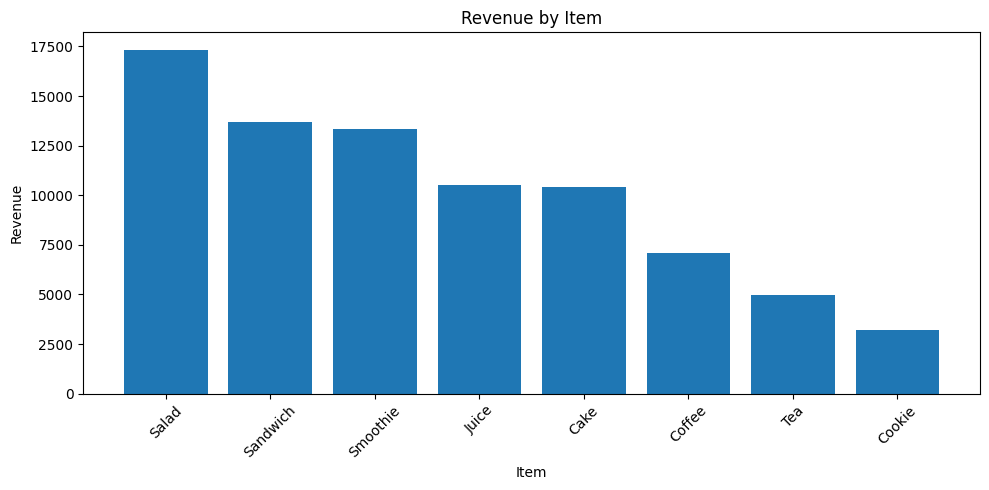

In [257]:
plt.figure(figsize=(10, 5))

plt.bar(
    item_analysis.index,
    item_analysis["Total_Revenue"]
)

plt.title("Revenue by Item")
plt.xlabel("Item")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.2 Quantity Sold by Item

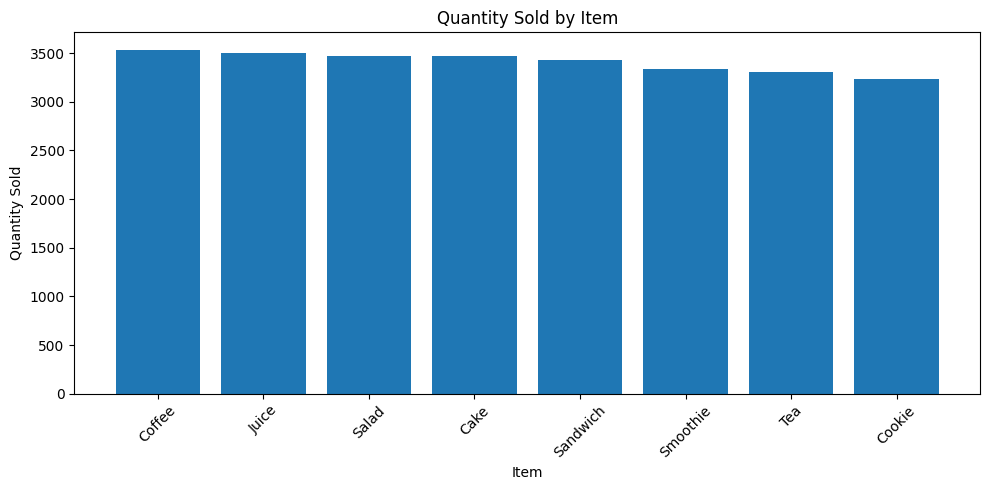

In [258]:
quantity_by_item = item_analysis.sort_values(
    "Total_Quantity",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    quantity_by_item.index,
    quantity_by_item["Total_Quantity"]
)

plt.title("Quantity Sold by Item")
plt.xlabel("Item")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.3 Monthly Revenue

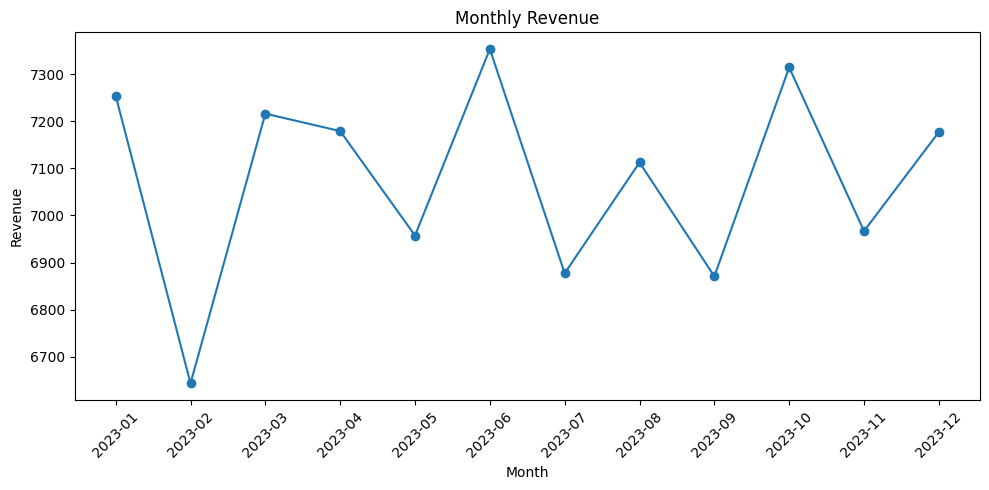

In [259]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["Total_Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.4 Monthly Transactions

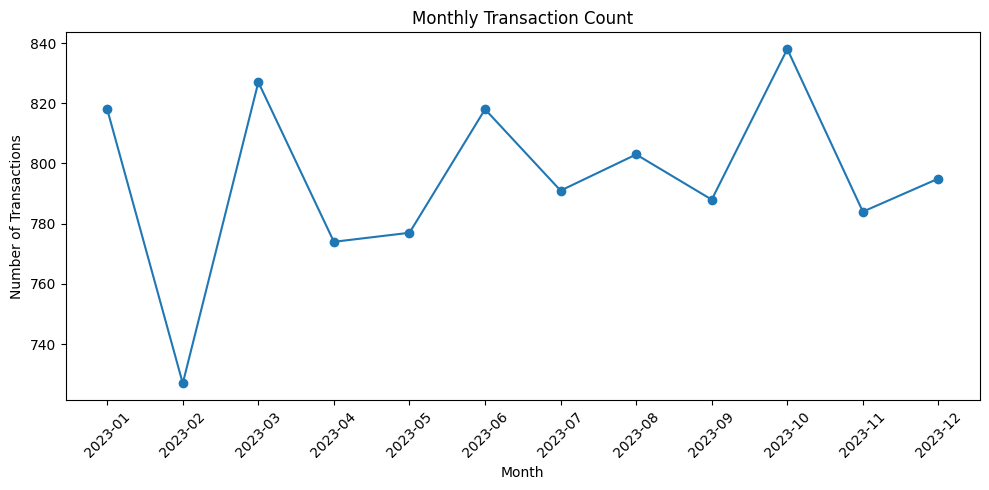

In [260]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["Transactions"],
    marker="o"
)

plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.5 Revenue by Payment Method

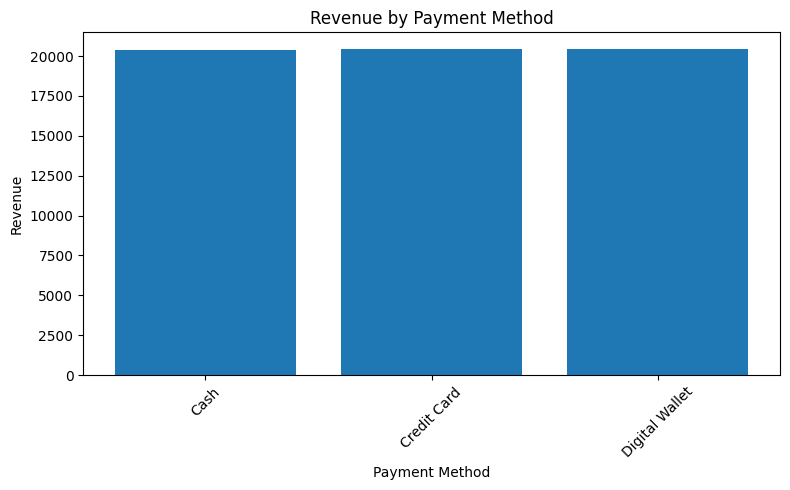

In [261]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_analysis.index,
    payment_analysis["Total_Revenue"]
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.6 Revenue by Location

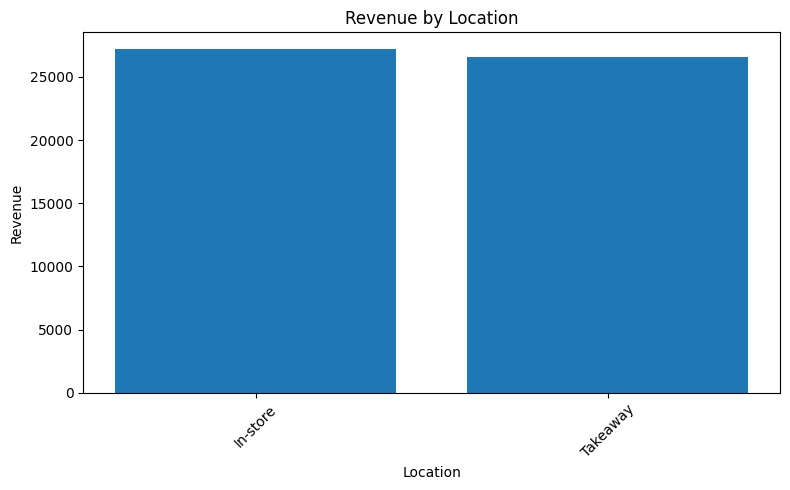

In [262]:
plt.figure(figsize=(8, 5))

plt.bar(
    location_analysis.index,
    location_analysis["Total_Revenue"]
)

plt.title("Revenue by Location")
plt.xlabel("Location")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.7 Transaction Value Distribution

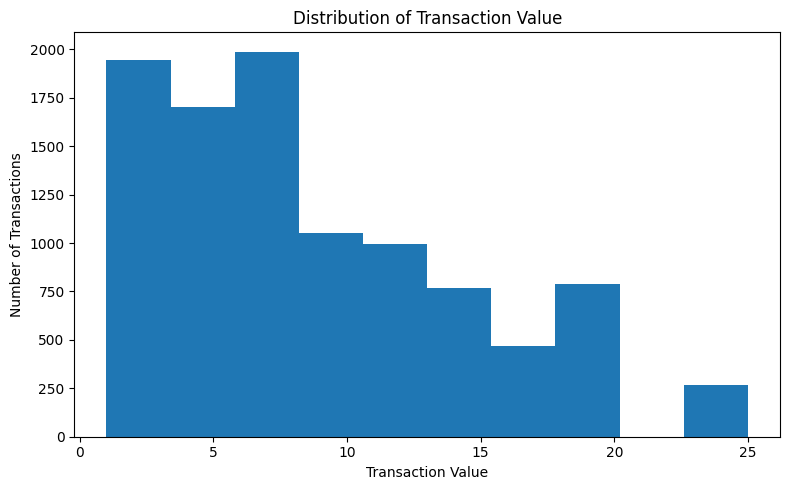

In [263]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Total Spent"].dropna(),
    bins=10
)

plt.title("Distribution of Transaction Value")
plt.xlabel("Transaction Value")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

### 8.8 Revenue by Day of Week

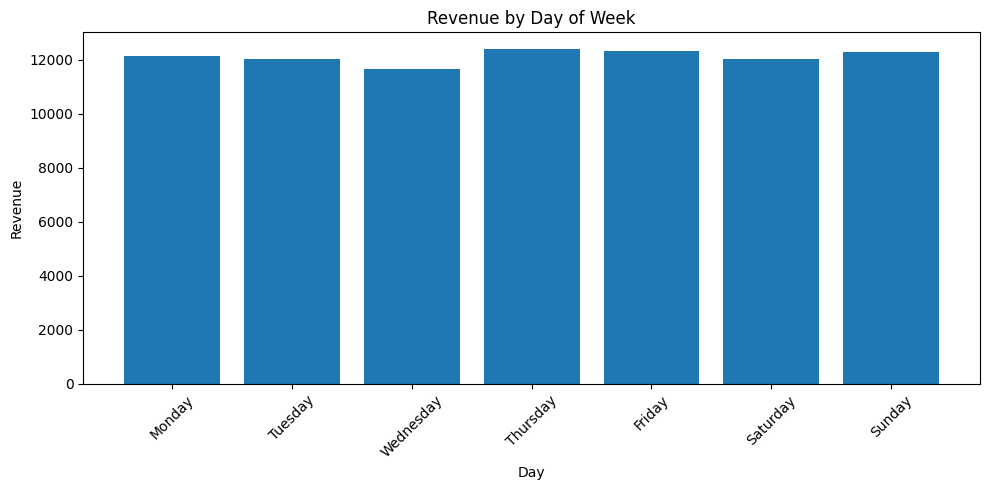

In [264]:
plt.figure(figsize=(10, 5))

plt.bar(
    day_analysis.index,
    day_analysis["Total_Revenue"]
)

plt.title("Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. SQL Data Preparation

Prepare the cleaned dataset for import into the SQL database.

### 9.1 Create SQL Dataset

In [265]:
# Select columns for SQL

sql_df = df[
    [
        "Transaction ID",
        "Item",
        "Quantity",
        "Price Per Unit",
        "Total Spent",
        "Payment Method",
        "Location",
        "Transaction Date"
    ]
].copy()

sql_df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


### 9.2 Format Transaction Date

In [266]:
# Format dates for MySQL

sql_df["Transaction Date"] = (
    sql_df["Transaction Date"]
    .dt.strftime("%Y-%m-%d")
)

### 9.3 Validate SQL Dataset

In [267]:
# Check final SQL dataset

print("Rows:", len(sql_df))
print("Columns:", sql_df.shape[1])

sql_df.info()

Rows: 10000
Columns: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              9031 non-null   object 
 2   Quantity          9977 non-null   float64
 3   Price Per Unit    9994 non-null   float64
 4   Total Spent       9977 non-null   float64
 5   Payment Method    6822 non-null   object 
 6   Location          6039 non-null   object 
 7   Transaction Date  9540 non-null   object 
dtypes: float64(3), object(5)
memory usage: 625.1+ KB


In [268]:
sql_df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [269]:
# Check missing values before SQL import

sql_df.isna().sum()

Transaction ID         0
Item                 969
Quantity              23
Price Per Unit         6
Total Spent           23
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

### 9.4 Export SQL Dataset

In [270]:
# Export cleaned dataset for MySQL import

sql_df.to_csv(
    "cafe_sales_sql.csv",
    index=False
)

## 10. Business Insights

### Product Performance

* Salad generated the highest revenue among the products, contributing approximately 17,345 in sales.
* Coffee had the highest quantity sold, with approximately 3,536 units.
* The difference between the highest-revenue product and highest-volume product shows that sales volume and revenue contribution are not always the same.

### Monthly Performance

* June recorded the highest monthly revenue at approximately 7,353.
* February recorded the lowest monthly revenue at approximately 6,644.
* October had the highest number of transactions, with approximately 838 transactions.

### Payment Methods

* Credit Card generated the highest recorded revenue among the available payment methods, at approximately 20,466.
* Cash and Digital Wallet showed relatively similar recorded revenue levels.
* Payment method analysis is limited because a significant portion of payment method values are missing.

### Location Performance

* In-store transactions generated slightly higher recorded revenue than Takeaway transactions.
* The comparison should be interpreted cautiously because many location values are missing.

### Transaction Value

* Most transactions fall within the lower transaction-value ranges.
* The average transaction value is approximately 8.93.
* Quantity and Total Spent show a moderate positive correlation of approximately 0.70, indicating that transactions with higher quantities generally tend to have higher total spending.

### Day-of-Week Performance

* Thursday recorded the highest revenue among the days of the week, at approximately 12,401.
* Wednesday recorded the lowest revenue, at approximately 11,680.50.

### Data Limitations

* Payment Method contains a substantial number of missing values.
* Location also contains a substantial number of missing values.
* Therefore, payment-method and location comparisons represent recorded values rather than the complete dataset.


## 11. Conclusion

This project analyzed 10,000 cafe transactions using Python, Pandas, NumPy, Matplotlib, and SQL data preparation techniques.

The project covered data inspection, cleaning, missing-value recovery, data-type conversion, validation, exploratory data analysis, visualization, and business insight generation.

The analysis identified product performance, monthly revenue patterns, payment-method trends, location performance, transaction-value distribution, and day-of-week sales patterns.

The cleaned dataset was also prepared for SQL/MySQL analysis, making the project useful as an end-to-end data analytics workflow.
